In [1]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wfdb

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [4]:
PROJECT_ROOT = Path("..")

PTBXL_DIR = PROJECT_ROOT / "data" / "raw" / "ptb-xl"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("PTB-XL:", PTBXL_DIR)
print("Processed:", PROCESSED_DIR)
print("Model:", MODELS_DIR)
print("Reports:", REPORTS_DIR)

PTB-XL: ../data/raw/ptb-xl
Processed: ../data/processed
Model: ../models
Reports: ../reports


In [5]:
train_df = pd.read_csv(PROCESSED_DIR / "ptbxl_train.csv")

val_df = pd.read_csv(PROCESSED_DIR / "ptbxl_val.csv")

test_df = pd.read_csv(PROCESSED_DIR / "ptbxl_test.csv")

print("Train:", train_df.shape)

print("Validation:", val_df.shape)

print("Test:", test_df.shape)

Train: (17084, 36)
Validation: (2146, 36)
Test: (2158, 36)


/tmp/ipykernel_9050/427596917.py:1: DtypeWarning: Columns (22: electrodes_problems, 24: pacemaker) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(PROCESSED_DIR / "ptbxl_train.csv")


In [6]:
TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

label_columns = [f"label_{cls}" for cls in TARGET_CLASSES]

print("Classes:", TARGET_CLASSES)

Classes: ['NORM', 'MI', 'STTC', 'CD', 'HYP']


In [7]:
def normalize_ecg(signal):
    """
    Normalize each ECG lead independently.
    """

    mean = signal.mean(axis=0, keepdims=True)

    std = signal.std(axis=0, keepdims=True)

    std = np.where(std < 1e-8, 1.0, std)

    return (signal - mean) / std

In [8]:
class PTBXLSignalDataset(Dataset):

    def __init__(self, dataframe, base_dir, label_columns):
        self.dataframe = dataframe.reset_index(drop=True)

        self.base_dir = Path(base_dir)

        self.label_columns = label_columns

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(
        self,
        index,
    ):
        row = self.dataframe.iloc[index]

        record_path = self.base_dir / row["filename_lr"]

        record = wfdb.rdrecord(str(record_path))

        signal = record.p_signal.astype(np.float32)

        signal = normalize_ecg(signal)

        # (samples, leads)
        # -> (leads, samples)
        signal = signal.T

        labels = row[label_columns].to_numpy(dtype=np.float32)

        return (
            torch.tensor(signal, dtype=torch.float32),
            torch.tensor(labels, dtype=torch.float32),
        )

In [9]:
val_dataset = PTBXLSignalDataset(val_df, PTBXL_DIR, label_columns)

test_dataset = PTBXLSignalDataset(test_df, PTBXL_DIR, label_columns)

print("Validation samples:", len(val_dataset))

print("Test samples:", len(test_dataset))

Validation samples: 2146
Test samples: 2158


In [10]:
BATCH_SIZE = 64

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

In [11]:
class ECGCNN(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [12]:
model = ECGCNN(num_classes=len(TARGET_CLASSES))

model = model.to(device)

model_path = MODELS_DIR / "ptbxl_cnn_baseline.pt"

model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))

model.eval()

print("Loaded model:", model_path)

Loaded model: ../models/ptbxl_cnn_baseline.pt


In [13]:
def predict(model, loader, device):

    model.eval()

    all_probabilities = []
    all_targets = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(device, non_blocking=True)

            logits = model(X)

            probabilities = torch.sigmoid(logits)

            all_probabilities.append(probabilities.cpu().numpy())

            all_targets.append(y.numpy())

    probabilities = np.concatenate(all_probabilities, axis=0)

    targets = np.concatenate(all_targets, axis=0)

    return (targets, probabilities)

In [14]:
y_val, y_val_prob = predict(model, val_loader, device)

print("Validation targets:", y_val.shape)

print("Validation probabilities:", y_val_prob.shape)

Validation targets: (2146, 5)
Validation probabilities: (2146, 5)


In [15]:
y_test, y_test_prob = predict(model, test_loader, device)

print("Test targets:", y_test.shape)

print("Test probabilities:", y_test_prob.shape)

Test targets: (2158, 5)
Test probabilities: (2158, 5)


In [16]:
val_roc_auc = {}

for i, class_name in enumerate(TARGET_CLASSES):

    val_roc_auc[class_name] = roc_auc_score(y_val[:, i], y_val_prob[:, i])

val_roc_auc_df = pd.DataFrame(
    {"class": list(val_roc_auc.keys()), "roc_auc": list(val_roc_auc.values())}
)

val_roc_auc_df

,class,roc_auc
0,NORM,0.934992
1,MI,0.917647
2,STTC,0.924691
3,CD,0.928030
4,HYP,0.818058


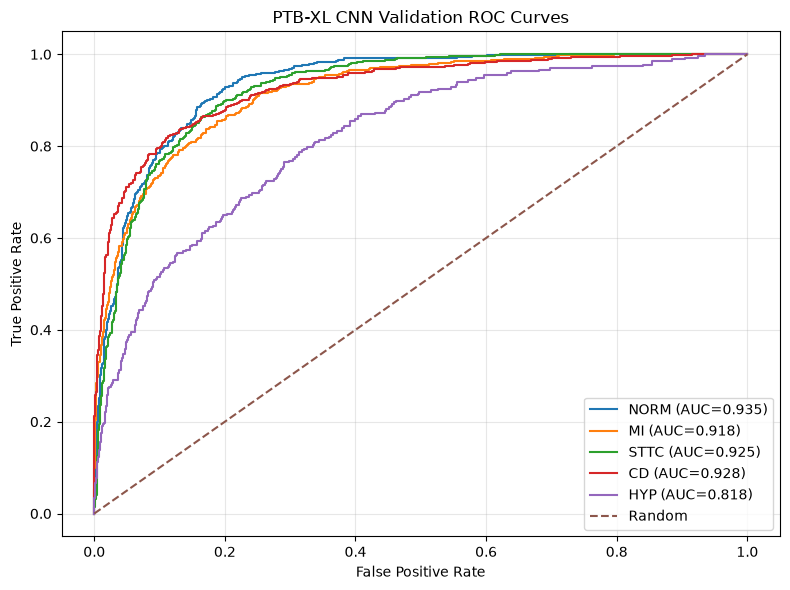

In [17]:
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(TARGET_CLASSES):

    fpr, tpr, _ = roc_curve(y_val[:, i], y_val_prob[:, i])

    plt.plot(fpr, tpr, label=(f"{class_name} " f"(AUC={val_roc_auc[class_name]:.3f})"))

plt.plot([0, 1], [0, 1], linestyle="--", label="Random")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("PTB-XL CNN Validation ROC Curves")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

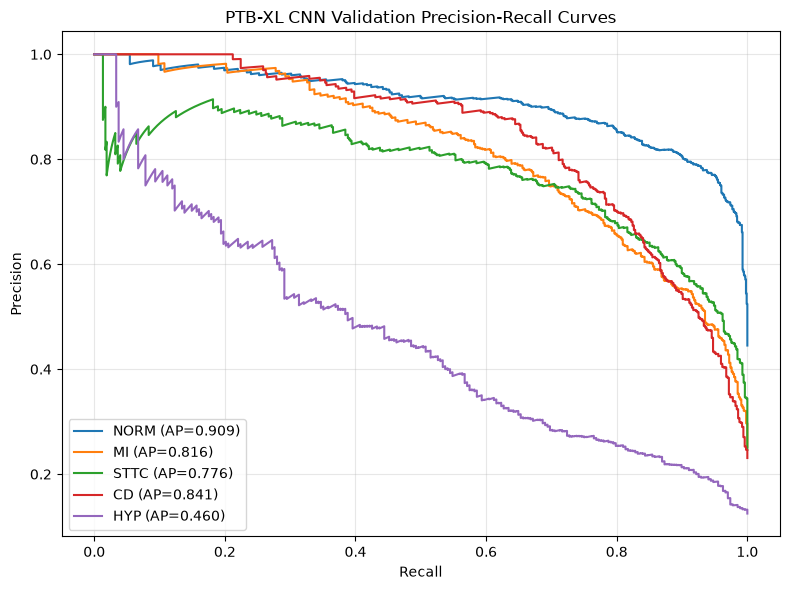

In [18]:
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(TARGET_CLASSES):

    precision, recall, _ = precision_recall_curve(y_val[:, i], y_val_prob[:, i])

    ap = average_precision_score(y_val[:, i], y_val_prob[:, i])

    plt.plot(recall, precision, label=(f"{class_name} " f"(AP={ap:.3f})"))

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("PTB-XL CNN Validation Precision-Recall Curves")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [19]:
BASELINE_THRESHOLD = 0.5

y_val_pred_05 = (y_val_prob >= BASELINE_THRESHOLD).astype(int)

baseline_val_f1 = f1_score(y_val, y_val_pred_05, average="macro", zero_division=0)

print(f"Validation Macro F1 " f"at threshold 0.5: " f"{baseline_val_f1:.4f}")

Validation Macro F1 at threshold 0.5: 0.6551


In [20]:
thresholds = np.arange(0.05, 0.96, 0.01)

best_thresholds = {}

threshold_results = []

for i, class_name in enumerate(TARGET_CLASSES):

    best_f1 = -1.0
    best_threshold = 0.5

    for threshold in thresholds:

        predictions = (y_val_prob[:, i] >= threshold).astype(int)

        current_f1 = f1_score(y_val[:, i], predictions, zero_division=0)

        if current_f1 > best_f1:

            best_f1 = current_f1

            best_threshold = threshold

    best_thresholds[class_name] = best_threshold

    threshold_results.append(
        {
            "class": class_name,
            "best_threshold": (best_threshold),
            "validation_f1": (best_f1),
        }
    )

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,class,best_threshold,validation_f1
0,NORM,0.47,0.852065
1,MI,0.21,0.728384
2,STTC,0.42,0.739650
3,CD,0.45,0.757804
4,HYP,0.23,0.472028


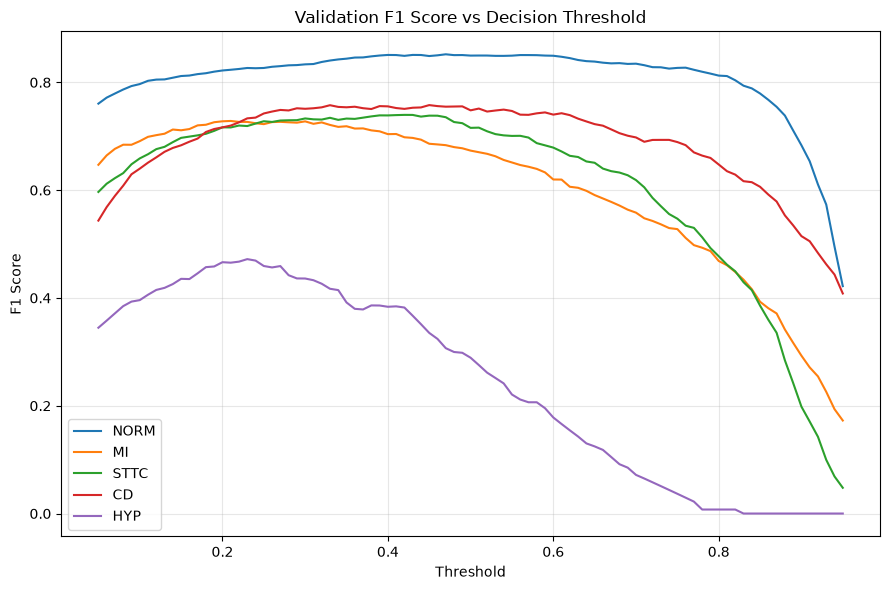

In [21]:
plt.figure(figsize=(9, 6))

for i, class_name in enumerate(TARGET_CLASSES):

    f1_scores = []

    for threshold in thresholds:

        predictions = (y_val_prob[:, i] >= threshold).astype(int)

        score = f1_score(
            y_val[:, i],
            predictions,
            zero_division=0,
        )

        f1_scores.append(score)

    plt.plot(
        thresholds,
        f1_scores,
        label=class_name,
    )

plt.xlabel("Threshold")

plt.ylabel("F1 Score")

plt.title("Validation F1 Score vs Decision Threshold")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [22]:
threshold_path = REPORTS_DIR / "ptbxl_cnn_thresholds.json"

with open(threshold_path, "w") as f:
    json.dump(best_thresholds, f, indent=4)

print("Saved thresholds:", threshold_path)

Saved thresholds: ../reports/ptbxl_cnn_thresholds.json


In [23]:
y_test_pred_tuned = np.zeros_like(y_test, dtype=int)

for i, class_name in enumerate(TARGET_CLASSES):

    threshold = best_thresholds[class_name]

    y_test_pred_tuned[:, i] = (y_test_prob[:, i] >= threshold).astype(int)

In [24]:
y_test_pred_05 = (y_test_prob >= 0.5).astype(int)

In [25]:
baseline_macro_f1 = f1_score(
    y_test,
    y_test_pred_05,
    average="macro",
    zero_division=0,
)

tuned_macro_f1 = f1_score(
    y_test,
    y_test_pred_tuned,
    average="macro",
    zero_division=0,
)

print(f"Test Macro F1 at 0.5: " f"{baseline_macro_f1:.4f}")

print(f"Test Macro F1 with tuned thresholds: " f"{tuned_macro_f1:.4f}")

Test Macro F1 at 0.5: 0.6470
Test Macro F1 with tuned thresholds: 0.7036


In [26]:
tuned_metrics = []

for i, class_name in enumerate(TARGET_CLASSES):

    y_true = y_test[:, i]

    y_pred = y_test_pred_tuned[:, i]

    tuned_metrics.append(
        {
            "class": class_name,
            "threshold": (best_thresholds[class_name]),
            "roc_auc": (roc_auc_score(y_true, y_test_prob[:, i])),
            "average_precision": (average_precision_score(y_true, y_test_prob[:, i])),
            "precision": (precision_score(y_true, y_pred, zero_division=0)),
            "recall": (recall_score(y_true, y_pred, zero_division=0)),
            "f1": (f1_score(y_true, y_pred, zero_division=0)),
        }
    )

tuned_metrics_df = pd.DataFrame(tuned_metrics)

tuned_metrics_df

,class,threshold,roc_auc,average_precision,precision,recall,f1
0,NORM,0.47,0.934506,0.910041,0.777293,0.924195,0.844402
1,MI,0.21,0.914057,0.797778,0.690164,0.765455,0.725862
2,STTC,0.42,0.927053,0.805714,0.739777,0.763916,0.751653
3,CD,0.45,0.913019,0.825923,0.801435,0.675403,0.733042
4,HYP,0.23,0.818934,0.469570,0.428571,0.503817,0.463158


In [27]:
specificity_results = []

for i, class_name in enumerate(TARGET_CLASSES):

    cm = confusion_matrix(
        y_test[:, i],
        y_test_pred_tuned[:, i],
        labels=[0, 1],
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    specificity_results.append(
        {
            "class": class_name,
            "true_negative": tn,
            "false_positive": fp,
            "false_negative": fn,
            "true_positive": tp,
            "specificity": specificity,
        }
    )

specificity_df = pd.DataFrame(specificity_results)

specificity_df

,class,true_negative,false_positive,false_negative,true_positive,specificity
0,NORM,940,255,73,890,0.786611
1,MI,1419,189,129,421,0.882463
2,STTC,1497,140,123,398,0.914478
3,CD,1579,83,161,335,0.950060
4,HYP,1720,176,130,132,0.907173


In [28]:
final_metrics_df = tuned_metrics_df.merge(
    specificity_df[["class", "specificity"]], on="class"
)

final_metrics_df

,class,threshold,roc_auc,average_precision,precision,recall,f1,specificity
0,NORM,0.47,0.934506,0.910041,0.777293,0.924195,0.844402,0.786611
1,MI,0.21,0.914057,0.797778,0.690164,0.765455,0.725862,0.882463
2,STTC,0.42,0.927053,0.805714,0.739777,0.763916,0.751653,0.914478
3,CD,0.45,0.913019,0.825923,0.801435,0.675403,0.733042,0.950060
4,HYP,0.23,0.818934,0.469570,0.428571,0.503817,0.463158,0.907173


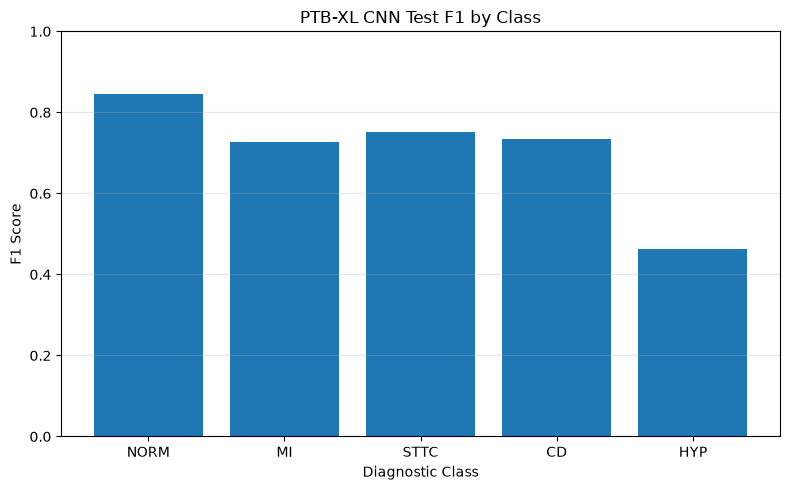

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    final_metrics_df["class"],
    final_metrics_df["f1"],
)

plt.xlabel("Diagnostic Class")

plt.ylabel("F1 Score")

plt.title("PTB-XL CNN Test F1 by Class")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

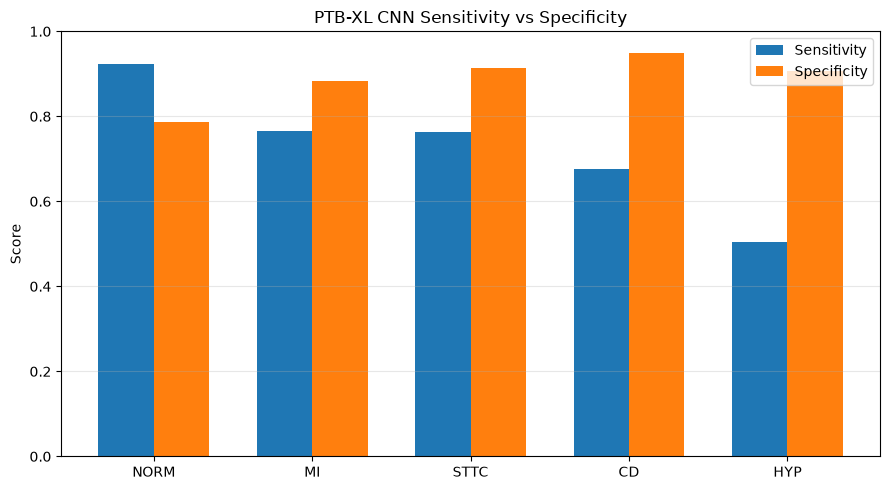

In [30]:
x = np.arange(len(TARGET_CLASSES))

width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width / 2, final_metrics_df["recall"], width, label="Sensitivity")

plt.bar(x + width / 2, final_metrics_df["specificity"], width, label="Specificity")

plt.xticks(x, TARGET_CLASSES)

plt.ylabel("Score")

plt.title("PTB-XL CNN Sensitivity vs Specificity")

plt.ylim(0, 1)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

In [31]:
overall_metrics = {
    "macro_roc_auc": roc_auc_score(y_test, y_test_prob, average="macro"),
    "micro_roc_auc": roc_auc_score(y_test, y_test_prob, average="micro"),
    "macro_average_precision": (
        average_precision_score(y_test, y_test_prob, average="macro")
    ),
    "micro_average_precision": (
        average_precision_score(y_test, y_test_prob, average="micro")
    ),
    "macro_f1": f1_score(y_test, y_test_pred_tuned, average="macro", zero_division=0),
    "micro_f1": f1_score(y_test, y_test_pred_tuned, average="micro", zero_division=0),
}

overall_metrics

{'macro_roc_auc': 0.9015137935191202,
 'micro_roc_auc': 0.9185377916828776,
 'macro_average_precision': 0.7618049559806542,
 'micro_average_precision': 0.8239133834262861,
 'macro_f1': 0.7036232637190534,
 'micro_f1': 0.7489244536224402}

In [32]:
final_metrics_df.to_csv(REPORTS_DIR / "ptbxl_cnn_final_class_metrics.csv", index=False)

with open(REPORTS_DIR / "ptbxl_cnn_final_metrics.json", "w") as f:
    json.dump(
        {key: float(value) for key, value in overall_metrics.items()}, f, indent=4
    )

print("Evaluation results saved.")

Evaluation results saved.


In [33]:
print("=" * 60)
print("PTB-XL CNN FINAL EVALUATION")
print("=" * 60)

print(f"Macro ROC-AUC: " f"{overall_metrics['macro_roc_auc']:.4f}")

print(f"Micro ROC-AUC: " f"{overall_metrics['micro_roc_auc']:.4f}")

print(f"Macro Average Precision: " f"{overall_metrics['macro_average_precision']:.4f}")

print(f"Micro Average Precision: " f"{overall_metrics['micro_average_precision']:.4f}")

print(f"Macro F1: " f"{overall_metrics['macro_f1']:.4f}")

print(f"Micro F1: " f"{overall_metrics['micro_f1']:.4f}")

print("\nPer-class results:")
print(final_metrics_df.to_string(index=False))

print("\nSelected thresholds:")
print(threshold_df)

PTB-XL CNN FINAL EVALUATION
Macro ROC-AUC: 0.9015
Micro ROC-AUC: 0.9185
Macro Average Precision: 0.7618
Micro Average Precision: 0.8239
Macro F1: 0.7036
Micro F1: 0.7489

Per-class results:
class  threshold  roc_auc  average_precision  precision   recall       f1  specificity
 NORM       0.47 0.934506           0.910041   0.777293 0.924195 0.844402     0.786611
   MI       0.21 0.914057           0.797778   0.690164 0.765455 0.725862     0.882463
 STTC       0.42 0.927053           0.805714   0.739777 0.763916 0.751653     0.914478
   CD       0.45 0.913019           0.825923   0.801435 0.675403 0.733042     0.950060
  HYP       0.23 0.818934           0.469570   0.428571 0.503817 0.463158     0.907173

Selected thresholds:
  class  best_threshold  validation_f1
0  NORM            0.47       0.852065
1    MI            0.21       0.728384
2  STTC            0.42       0.739650
3    CD            0.45       0.757804
4   HYP            0.23       0.472028
